# First Passage Time Simulation

## Introduction

The goal of this Jupyter notebook is to create a faster, more accurate, and more versatile version of the first passage time simulation for various graphs from the paper

> **Vertex Centrality Reconstruction in an Inverse Problem for Information Diffusion**
> Yixian Gao, Songshuo Li, and Yang Yang (arXiv:2603.20710, 2026)

## Reconstruction (Python)

Reconstruction of the Section 5 simulation. Run the setup cell and the *Main functions* cells once, then run any experiment.

In [1]:
from functools import lru_cache

import matplotlib.pyplot as plt
import numpy as np
import torch

from graph import *

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type != "cuda":
    print("CUDA not available")

device: cpu
CUDA not available


## Experiment 1: a graph with eight vertices

Constant ground-truth $\mu$ (Section 5.1, Figure 1): a $2 \times 4$ ladder with $|B| = 3$, $|X\setminus B| = 5$, $w_{xy} = 0.25$, $\mu_x = 1$, $T = 9$. The observed vertices are the right three vertices of the top row. Paper FRNE: $0.248499\%$.

Check of Assumption 1 (ii): every vertex has degree $\le 3$, so $\sum_y w_{xy} \le 0.75 \le 1 = \mu_x$.

Change any value in the parameter cell to run a variant.

In [8]:
# ---- parameters (edit me) ----
grid1    = GridGraph.make_grid(2, 4)                      # 2 x 4 ladder, row 0 on top
B1_coord = [(0, 1), (0, 2), (1, 3)]             # observed vertices
w1       = 0.25                                 # edge weight
mu1_kind = "constant"                           # "constant", "deg", or an array of length |X|
mu1_val  = 1.0                                  # used when mu1_kind = "constant"
T1       = 9                                    # needs T >= |X|
N1       = 10**6                                # Monte Carlo walks per pair (x, y)
seed1    = 0

|X| = 8, |B| = 3, T = 9, t_max = 17


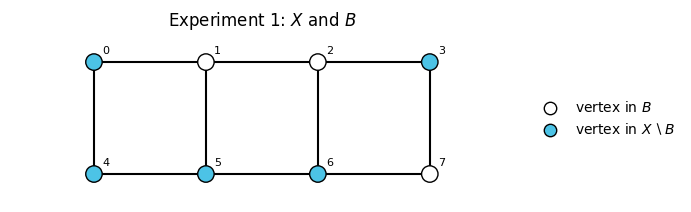

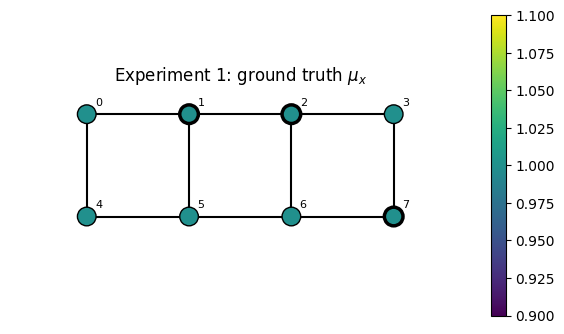

In [9]:
G1 = GridGraph(grid1, B1_coord, w=w1, mu=mu1_kind, mu_val=mu1_val)
W1, mu1, B1 = G1.W, G1.mu, G1.B
P1 = G1.transition_matrix()
t_max1 = 2 * T1 - 1                             # data needed for t = 1, ..., 2T-1
print(f"|X| = {len(mu1)}, |B| = {len(B1)}, T = {T1}, t_max = {t_max1}")

plot_graph(grid1, B1, title="Experiment 1: $X$ and $B$")
plot_graph(grid1, B1, values=mu1, title=r"Experiment 1: ground truth $\mu_x$")
plt.show()

In [5]:
r1_lit = exact_first_passage_literal(P1, B1, t_max1)
r1_emp = empirical_first_passage(P1, B1, t_max1, n_walks=N1, seed=seed1)

#summarize(P1, B1, r1_emp, r_lit=r1_lit, paper_frne=0.248499)

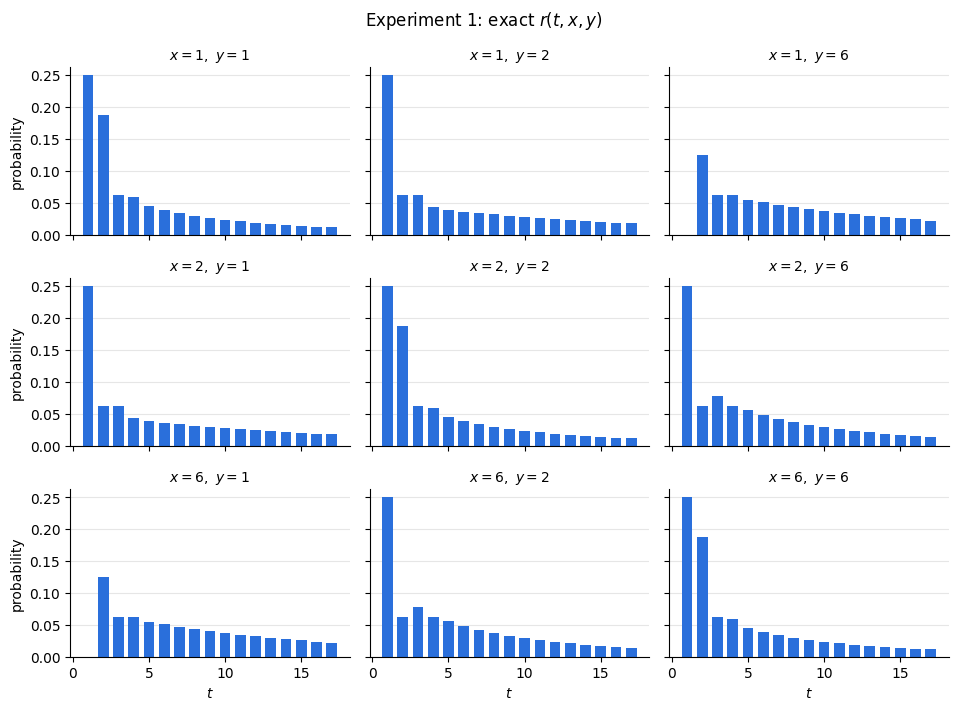

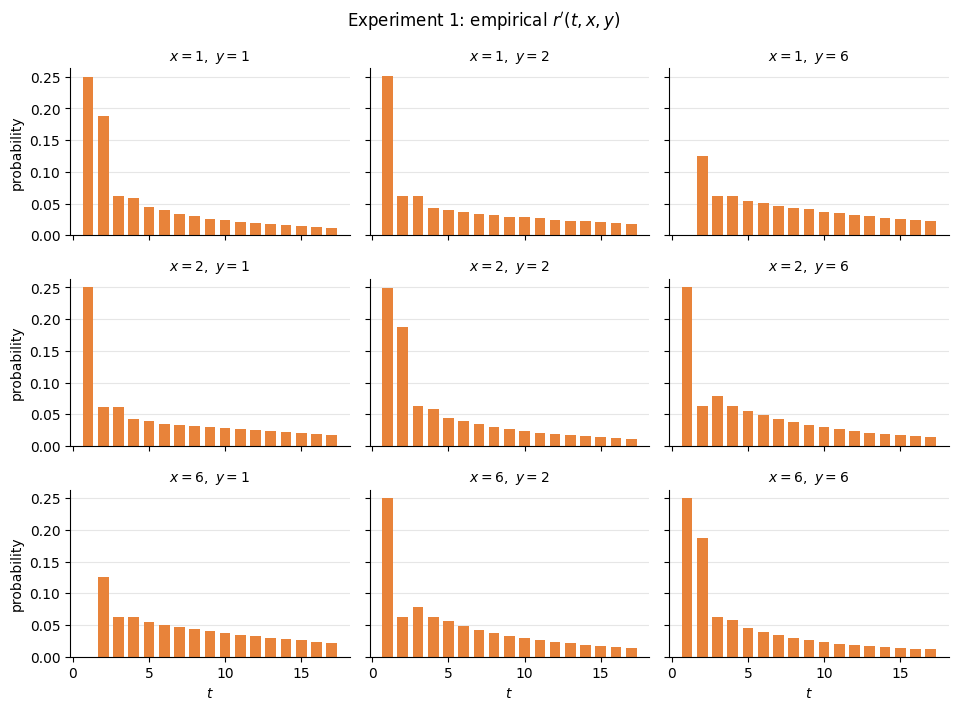

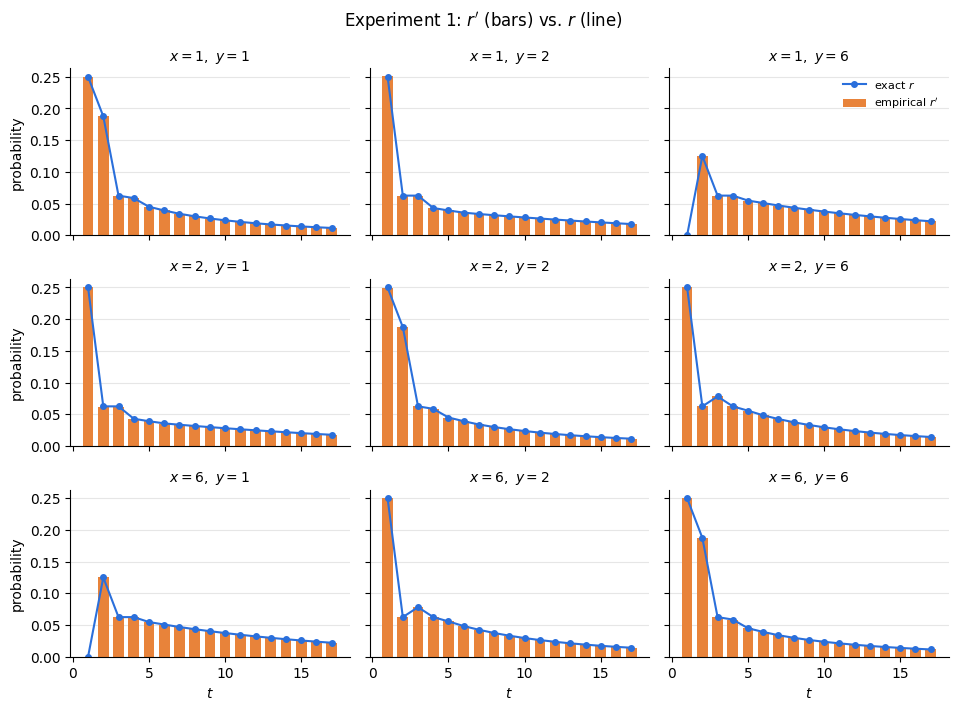

In [6]:
plot_exact_distribution(r1_lit, B1, title="Experiment 1: exact $r(t, x, y)$")
plot_empirical_distribution(r1_emp, B1, title="Experiment 1: empirical $r'(t, x, y)$")
plot_empirical_distribution(r1_emp, B1, r=r1_lit, title="Experiment 1: $r'$ (bars) vs. $r$ (line)")
plt.show()

### Experiment 1: all subsets of $B$

For every size $|B|=1,\ldots,7$, evaluate every possible subset of vertices (254 subsets total). The box plot shows the distribution of FRNE values for each size. The cell also reports the best subset at each size and the overall lowest-FRNE subset. These are Monte Carlo estimates; increase `N1_sweep` to reduce sampling noise, at the cost of a longer run.

Evaluated 254 subsets.
|B|=1: best FRNE=0.859483%; vertices=[(0, 0)]; indices=(0,)
|B|=2: best FRNE=1.675590%; vertices=[(0, 3), (1, 0)]; indices=(3, 4)
|B|=3: best FRNE=1.725767%; vertices=[(0, 0), (1, 0), (1, 3)]; indices=(0, 4, 7)
|B|=4: best FRNE=1.948475%; vertices=[(0, 0), (0, 3), (1, 0), (1, 3)]; indices=(0, 3, 4, 7)
|B|=5: best FRNE=2.214404%; vertices=[(0, 0), (0, 3), (1, 0), (1, 2), (1, 3)]; indices=(0, 3, 4, 6, 7)
|B|=6: best FRNE=2.667906%; vertices=[(0, 0), (0, 1), (1, 0), (1, 1), (1, 2), (1, 3)]; indices=(0, 1, 4, 5, 6, 7)
|B|=7: best FRNE=2.783272%; vertices=[(0, 0), (0, 1), (0, 2), (0, 3), (1, 0), (1, 1), (1, 3)]; indices=(0, 1, 2, 3, 4, 5, 7)
Overall best subset: {'size': 1, 'indices': (0,), 'vertices': ((0, 0),), 'frne': 0.8594828718113268}


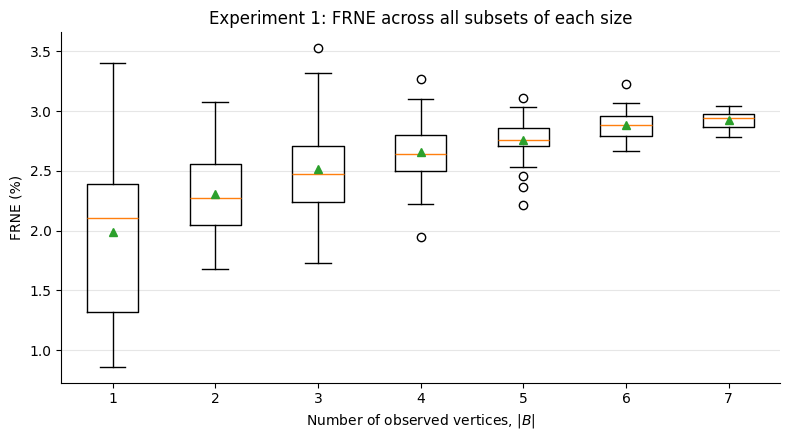

In [7]:
from itertools import combinations

N1_sweep = 10**4  # Monte Carlo walks per ordered pair, for each subset
B1_sweep_sizes = list(range(1, len(grid1)))
B1_sweep_frne = {nB: [] for nB in B1_sweep_sizes}
B1_sweep_results = []

for nB in B1_sweep_sizes:
    for vertex_indices in combinations(range(len(grid1)), nB):
        B_coords = [grid1[i] for i in vertex_indices]
        B_sweep = torch.tensor([G1.index[coord] for coord in B_coords], dtype=torch.long)
        r_exact = exact_first_passage_literal(P1, B_sweep, t_max1)
        subset_seed = seed1 + sum(1 << i for i in vertex_indices)
        r_empirical = empirical_first_passage(
            P1, B_sweep, t_max1, n_walks=N1_sweep,
            batch=min(10**4, N1_sweep), seed=subset_seed
        )
        subset_frne = frne(r_exact, r_empirical)
        B1_sweep_frne[nB].append(subset_frne)
        B1_sweep_results.append({
            "size": nB,
            "indices": vertex_indices,
            "vertices": tuple(B_coords),
            "frne": subset_frne,
        })

B1_best_by_size = {
    nB: min((result for result in B1_sweep_results if result["size"] == nB),
            key=lambda result: result["frne"])
    for nB in B1_sweep_sizes
}
B1_best_overall = min(B1_sweep_results, key=lambda result: result["frne"])

print(f"Evaluated {len(B1_sweep_results)} subsets.")
for nB, result in B1_best_by_size.items():
    print(f"|B|={nB}: best FRNE={result['frne']:.6f}%; "
          f"vertices={list(result['vertices'])}; indices={result['indices']}")
print("Overall best subset:", B1_best_overall)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([B1_sweep_frne[nB] for nB in B1_sweep_sizes],
           positions=B1_sweep_sizes, showmeans=True)
ax.set_xticks(B1_sweep_sizes)
ax.set_xlabel(r"Number of observed vertices, $|B|$")
ax.set_ylabel("FRNE (%)")
ax.set_title("Experiment 1: FRNE across all subsets of each size")
ax.grid(axis="y", color="0.9")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

### Experiment 1: all subsets of $B$ with absorption

Repeat the all-subsets experiment with a uniform absorption probability $q(x)=0.1$. Absorption replaces part of the hold probability; walks absorbed before first passage contribute no finite first-passage event, and the distributions are not conditioned on survival. The box plot compares FRNE across all 254 nonempty, non-full subsets, and the results report the lowest-FRNE subset for each size and overall.

q(x) = 0.1; minimum p_xx = 0.25
survival probability through t_max, by starting vertex: [0.1668 0.1668 0.1668 0.1668 0.1668 0.1668 0.1668 0.1668]
Evaluated 254 subsets with absorption.
|B|=1: best FRNE=0.897311%; vertices=[(0, 0)]; indices=(0,)
|B|=2: best FRNE=1.576936%; vertices=[(0, 3), (1, 0)]; indices=(3, 4)
|B|=3: best FRNE=1.559388%; vertices=[(0, 0), (1, 0), (1, 3)]; indices=(0, 4, 7)
|B|=4: best FRNE=2.088434%; vertices=[(0, 3), (1, 0), (1, 2), (1, 3)]; indices=(3, 4, 6, 7)
|B|=5: best FRNE=2.282729%; vertices=[(0, 0), (0, 1), (0, 3), (1, 0), (1, 1)]; indices=(0, 1, 3, 4, 5)
|B|=6: best FRNE=2.413049%; vertices=[(0, 0), (0, 1), (0, 2), (0, 3), (1, 0), (1, 1)]; indices=(0, 1, 2, 3, 4, 5)
|B|=7: best FRNE=2.582764%; vertices=[(0, 0), (0, 1), (0, 2), (0, 3), (1, 0), (1, 1), (1, 2)]; indices=(0, 1, 2, 3, 4, 5, 6)
Overall best subset with absorption: {'size': 1, 'indices': (0,), 'vertices': ((0, 0),), 'frne': 0.8973106568727132}


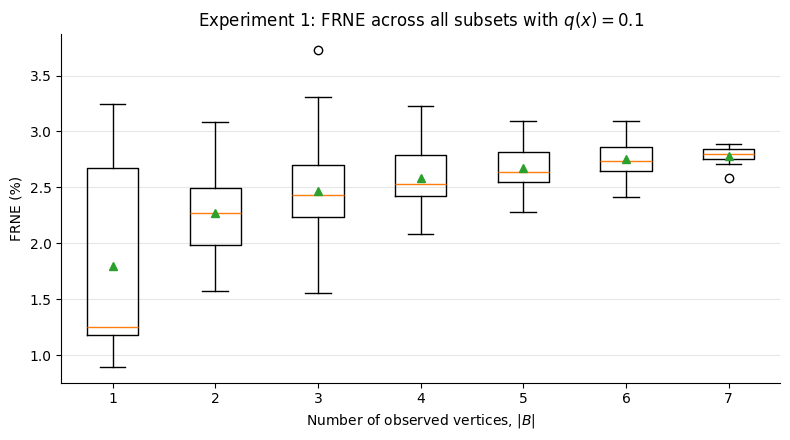

In [4]:
from itertools import combinations

q1_abs = torch.full((G1.n,), 0.1, dtype=torch.float64)
P1_abs = P1 - torch.diag(q1_abs)
assert torch.all(q1_abs <= torch.diagonal(P1))
print(f"q(x) = 0.1; minimum p_xx = {torch.diagonal(P1).min().item():.2f}")
print("survival probability through t_max, by starting vertex:",
      torch.linalg.matrix_power(P1_abs, t_max1).sum(dim=1).numpy().round(4))

N1_abs_sweep = 10**4  # Monte Carlo walks per ordered pair, for each subset
B1_abs_sweep_sizes = list(range(1, G1.n))
B1_abs_sweep_frne = {nB: [] for nB in B1_abs_sweep_sizes}
B1_abs_sweep_results = []

for nB in B1_abs_sweep_sizes:
    for vertex_indices in combinations(range(G1.n), nB):
        B_coords_abs = [grid1[i] for i in vertex_indices]
        B_abs = torch.tensor([G1.index[coord] for coord in B_coords_abs], dtype=torch.long)
        r_exact_abs = exact_first_passage_literal(P1, B_abs, t_max1, q=q1_abs)
        subset_seed_abs = seed1 + 10_000 + sum(1 << i for i in vertex_indices)
        r_empirical_abs = empirical_first_passage(
            P1, B_abs, t_max1, n_walks=N1_abs_sweep,
            batch=min(10**4, N1_abs_sweep), seed=subset_seed_abs, q=q1_abs
        )
        subset_frne_abs = frne(r_exact_abs, r_empirical_abs)
        B1_abs_sweep_frne[nB].append(subset_frne_abs)
        B1_abs_sweep_results.append({
            "size": nB,
            "indices": vertex_indices,
            "vertices": tuple(B_coords_abs),
            "frne": subset_frne_abs,
        })

B1_abs_best_by_size = {
    nB: min((result for result in B1_abs_sweep_results if result["size"] == nB),
            key=lambda result: result["frne"])
    for nB in B1_abs_sweep_sizes
}
B1_abs_best_overall = min(B1_abs_sweep_results, key=lambda result: result["frne"])

print(f"Evaluated {len(B1_abs_sweep_results)} subsets with absorption.")
for nB, result in B1_abs_best_by_size.items():
    print(f"|B|={nB}: best FRNE={result['frne']:.6f}%; "
          f"vertices={list(result['vertices'])}; indices={result['indices']}")
print("Overall best subset with absorption:", B1_abs_best_overall)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([B1_abs_sweep_frne[nB] for nB in B1_abs_sweep_sizes],
           positions=B1_abs_sweep_sizes, showmeans=True)
ax.set_xticks(B1_abs_sweep_sizes)
ax.set_xlabel(r"Number of observed vertices, $|B|$")
ax.set_ylabel("FRNE (%)")
ax.set_title(r"Experiment 1: FRNE across all subsets with $q(x)=0.1$")
ax.grid(axis="y", color="0.9")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

### Experiment 1: reconstructing an unknown absorption potential

Keep the eight-vertex ladder and the original three observed vertices fixed. Treat the transition matrix $P$ and observation set $B$ as known, and reconstruct an unknown, vertex-dependent potential $q$ from the first-passage distributions for ordered pairs in $B\times B$. A heterogeneous $q$ is used only to generate synthetic observations; the fitting routine receives the graph, $B$, and the observed distributions, not the true potential. For each horizon $T$, observations include times $1,\ldots,2T-1$. The fit is bounded nonlinear least squares with $0\leq q(x)\leq p_{xx}$.

The experiment reports relative $\ell_2$ error in $q$ over repeated Monte Carlo samples and the rank of the local sensitivity matrix. Full rank indicates local identifiability at the chosen true potential, not a proof of global uniqueness. Finite-sample error need not decrease monotonically with every increase in $T$.

Relative potential error (%), mean +/- SD over repetitions; local sensitivity rank:
T= 2 (t_max= 3): 20.79% +/- 10.52%; rank=5/8
T= 3 (t_max= 5): 30.11% +/- 13.53%; rank=8/8
T= 4 (t_max= 7): 23.38% +/- 7.89%; rank=8/8
T= 5 (t_max= 9): 21.67% +/- 8.96%; rank=8/8
T= 6 (t_max=11): 20.51% +/- 8.25%; rank=8/8
T= 8 (t_max=15): 18.86% +/- 7.26%; rank=8/8
T=10 (t_max=19): 18.83% +/- 7.24%; rank=8/8
T=12 (t_max=23): 19.09% +/- 6.86%; rank=8/8
T=15 (t_max=29): 18.94% +/- 6.81%; rank=8/8

True and mean estimated potential at T=15:
(0, 0): true=0.040, estimated=0.044
(0, 1): true=0.070, estimated=0.071
(0, 2): true=0.100, estimated=0.100
(0, 3): true=0.130, estimated=0.150
(1, 0): true=0.060, estimated=0.057
(1, 1): true=0.090, estimated=0.095
(1, 2): true=0.120, estimated=0.097
(1, 3): true=0.150, estimated=0.150


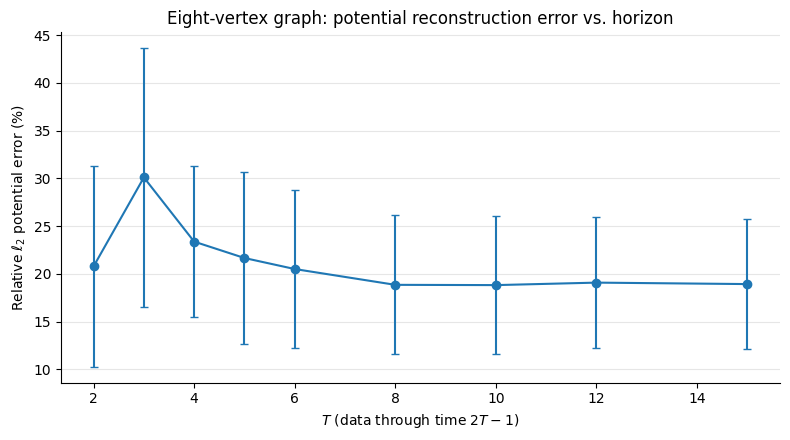

In [10]:
# Rebuild the graph explicitly so later notebook cells can change G1 or B1 safely.
G1_recon = GridGraph(grid1, B1_coord, w=w1, mu=mu1_kind, mu_val=mu1_val)
P1_recon, B1_recon = G1_recon.transition_matrix(), G1_recon.B
q_true_recon = torch.tensor([0.04, 0.07, 0.10, 0.13, 0.06, 0.09, 0.12, 0.15], dtype=torch.float64)
q_upper_recon = torch.diagonal(P1_recon)
assert torch.all(q_true_recon >= 0) and torch.all(q_true_recon <= q_upper_recon)

def first_passage_model(q, t_max):
    """Differentiable exact first-passage distributions for all pairs in B."""
    K = P1_recon - torch.diag(q)
    per_target = []
    for y in B1_recon.tolist():
        r = K[:, y]
        by_time = [r[B1_recon]]
        avoid_target = torch.arange(G1_recon.n) != y
        for _ in range(1, t_max):
            r = K[:, avoid_target] @ r[avoid_target]
            by_time.append(r[B1_recon])
        per_target.append(torch.stack(by_time))
    return torch.stack(per_target, dim=2)

# Check the differentiable model against the shared exact implementation.
T1_recon_values = [2, 3, 4, 5, 6, 8, 10, 12, 15]
t_max1_recon = 2 * max(T1_recon_values) - 1
assert torch.allclose(
    first_passage_model(q_true_recon, t_max1_recon),
    exact_first_passage_literal(P1_recon, B1_recon, t_max1_recon, q=q_true_recon),
    atol=1e-12,
)

def fit_potential(observed, t_max):
    best_loss, best_q = float("inf"), None
    for initial_q in (0.08, 0.16):
        initial_fraction = (torch.full_like(q_upper_recon, initial_q) / q_upper_recon).clamp(1e-5, 1 - 1e-5)
        theta = torch.nn.Parameter(torch.logit(initial_fraction))
        optimizer = torch.optim.LBFGS(
            [theta], lr=0.8, max_iter=80, tolerance_grad=1e-9,
            tolerance_change=1e-12, line_search_fn="strong_wolfe"
        )

        def closure():
            optimizer.zero_grad()
            q_estimate = q_upper_recon * torch.sigmoid(theta)
            prediction = first_passage_model(q_estimate, t_max)
            loss = torch.mean((prediction - observed[:t_max]) ** 2)
            loss.backward()
            return loss

        optimizer.step(closure)
        q_estimate = q_upper_recon * torch.sigmoid(theta.detach())
        final_loss = torch.mean((first_passage_model(q_estimate, t_max) - observed[:t_max]) ** 2).item()
        if final_loss < best_loss:
            best_loss, best_q = final_loss, q_estimate
    return best_q

N1_recon = 20_000       # walks per ordered observed pair and repetition
repeats1_recon = 5      # independent Monte Carlo data sets
seed1_recon = 20_260
relative_q_errors = {T: [] for T in T1_recon_values}
q_estimates_by_T = {T: [] for T in T1_recon_values}
sensitivity_rank_by_T = {}

for T in T1_recon_values:
    J = torch.autograd.functional.jacobian(
        lambda q: first_passage_model(q, 2 * T - 1).reshape(-1), q_true_recon
    )
    sensitivity_rank_by_T[T] = int(torch.linalg.matrix_rank(J).item())

for repetition in range(repeats1_recon):
    observations = empirical_first_passage(
        P1_recon, B1_recon, t_max1_recon, n_walks=N1_recon,
        batch=10_000, seed=seed1_recon + repetition, q=q_true_recon
    )
    for T in T1_recon_values:
        t_max = 2 * T - 1
        q_estimate = fit_potential(observations, t_max)
        relative_error = 100 * torch.linalg.vector_norm(q_estimate - q_true_recon) / torch.linalg.vector_norm(q_true_recon)
        relative_q_errors[T].append(relative_error.item())
        q_estimates_by_T[T].append(q_estimate)

mean_q_error = [float(np.mean(relative_q_errors[T])) for T in T1_recon_values]
std_q_error = [float(np.std(relative_q_errors[T], ddof=1)) for T in T1_recon_values]
print("Relative potential error (%), mean +/- SD over repetitions; local sensitivity rank:")
for T, mean_error, std_error in zip(T1_recon_values, mean_q_error, std_q_error):
    print(f"T={T:2d} (t_max={2*T-1:2d}): {mean_error:.2f}% +/- {std_error:.2f}%; "
          f"rank={sensitivity_rank_by_T[T]}/{G1_recon.n}")

q_estimate_longest = torch.stack(q_estimates_by_T[T1_recon_values[-1]]).mean(dim=0)
print(f"\nTrue and mean estimated potential at T={T1_recon_values[-1]}:")
for vertex, q_true, q_estimate in zip(grid1, q_true_recon.tolist(), q_estimate_longest.tolist()):
    print(f"{vertex}: true={q_true:.3f}, estimated={q_estimate:.3f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(T1_recon_values, mean_q_error, yerr=std_q_error, marker="o", capsize=3, lw=1.5)
ax.set(xlabel="$T$ (data through time $2T-1$)", ylabel="Relative $\\ell_2$ potential error (%)",
       title="Eight-vertex graph: potential reconstruction error vs. horizon")
ax.grid(axis="y", color="0.9")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

### Experiment 1: Testing Values for T

q(x) = 0.1; minimum p_xx = 0.25
survival probability through t_max, by starting vertex: [0.1668 0.1668 0.1668 0.1668 0.1668 0.1668 0.1668 0.1668]


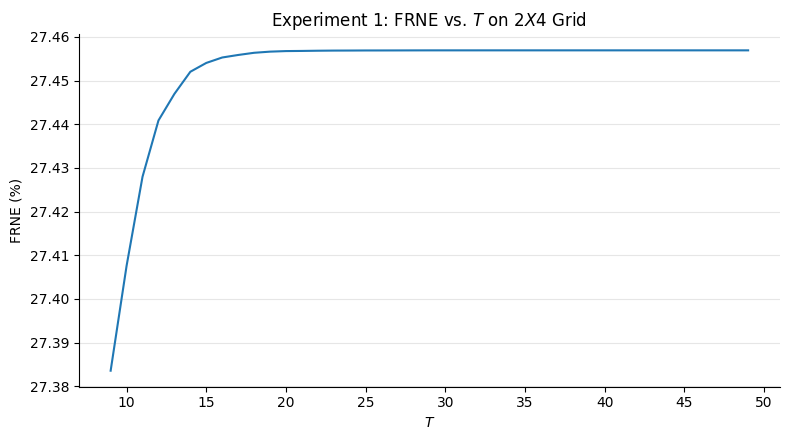

In [6]:
# ---- parameters (edit me) ----
grid1    = GridGraph.make_grid(2, 4)                      # 2 x 4 ladder, row 0 on top
B1_coord = [(0, 0), (1, 0), (1, 3)]             # observed vertices
w1       = 0.25                                 # edge weight
mu1_kind = "constant"                           # "constant", "deg", or an array of length |X|
mu1_val  = 1.0                                  # used when mu1_kind = "constant"
N1       = 10**6                                # Monte Carlo walks per pair (x, y)
seed1    = 0

G1 = GridGraph(grid1, B1_coord, w=w1, mu=mu1_kind, mu_val=mu1_val)
W1, mu1, B1 = G1.W, G1.mu, G1.B
P1 = G1.transition_matrix()

q1_abs = torch.full((G1.n,), 0.1, dtype=torch.float64)
P1_abs = P1 - torch.diag(q1_abs)
assert torch.all(q1_abs <= torch.diagonal(P1))
print(f"q(x) = 0.1; minimum p_xx = {torch.diagonal(P1).min().item():.2f}")
print("survival probability through t_max, by starting vertex:",
      torch.linalg.matrix_power(P1_abs, t_max1).sum(dim=1).numpy().round(4))

N1_T_sweep = 20_000
seed1_T_sweep = 500
T1_values = list(range(G1.n + 1, 50))
t_max1_sweep = 2 * T1_values[-1] - 1
r1_exact_sweep = exact_first_passage_literal(P1_abs, B1, t_max1_sweep, q=q1_abs)
r1_emp_sweep = empirical_first_passage(
    P1_abs, B1, t_max1_sweep, n_walks=N1_T_sweep,
    batch=10_000, seed=seed1_T_sweep
)
FRNE1_by_T = [
    frne(r1_exact_sweep[:2 * T - 1], r1_emp_sweep[:2 * T - 1])
    for T in T1_values
]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(T1_values, FRNE1_by_T, lw=1.5)
ax.set(xlabel="$T$", ylabel="FRNE (%)",
       title="Experiment 1: FRNE vs. $T$ on $2 X 4$ Grid")
ax.grid(axis="y", color="0.9")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()